# 01 - Data understanding, EDA and decomposition
Dataset: Kaggle *Store Item Demand Forecasting Challenge* (10 stores x 50 items, daily units, 2013-01-01 to 2017-12-31).

In [1]:
import json, sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, display
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
from src import config as C
show = lambda name: display(Image(filename=str(C.IMAGES / name)))

## Data quality

In [2]:
q = json.loads((C.REPORTS / 'data_quality.json').read_text())
print(json.dumps(q['raw_profile'], indent=1))
print(json.dumps(q['cleaning_log'], indent=1))

{
 "rows": 913000,
 "columns": [
  "date",
  "store",
  "item",
  "sales"
 ],
 "dtypes": {
  "date": "datetime64[us]",
  "store": "int64",
  "item": "int64",
  "sales": "int64"
 },
 "missing_values": {
  "date": 0,
  "store": 0,
  "item": 0,
  "sales": 0
 },
 "exact_duplicates": 0,
 "repeated_keys": 0,
 "stores": 10,
 "items": 50,
 "series": 500,
 "date_min": "2013-01-01",
 "date_max": "2017-12-31",
 "calendar_days": 1826,
 "missing_calendar_dates": 0,
 "series_with_incomplete_history": 0,
 "negative_sales": 0,
 "zero_share": 1.095290251916758e-06,
 "skew": 0.8671122960235801,
 "summary": {
  "count": 913000.0,
  "mean": 52.250286966046005,
  "std": 28.801143603517097,
  "min": 0.0,
  "25%": 30.0,
  "50%": 47.0,
  "75%": 70.0,
  "max": 231.0
 }
}
{
 "exact_duplicates_removed": 0,
 "repeated_keys_found": 0,
 "negative_sales_set_missing": 0,
 "records_added_by_calendar_reindex": 0,
 "missing_after_imputation": 0,
 "outliers_flagged": 1175,
 "outlier_share": 0.0012869660460021906,
 "outli

The data is complete: no missing days, no duplicates, no negatives and a single zero-sales record. 1,175 points (0.13%) were flagged as statistical outliers using a robust z-score against the same store-item-weekday-year median. They were investigated and **kept**, because only a small share fall on holidays and nothing shows they are recording errors.

In [3]:
pd.read_csv(C.REPORTS / 'flagged_outliers.csv').head(10)

,date,store,item,sales,year,dow,robust_z,is_outlier
0,2014-01-15,6,4,0,2014,2,-11.292243,True
1,2014-01-09,7,1,1,2014,3,-8.401903,True
2,2015-12-31,7,1,1,2015,3,-8.401903,True
3,2013-12-30,1,27,1,2013,0,-8.114211,True
4,2016-01-05,5,4,2,2016,1,-7.471421,True
5,2013-12-12,7,5,1,2013,3,-7.293952,True
6,2014-12-09,5,4,2,2014,1,-7.233077,True
7,2017-01-20,7,5,2,2017,4,-7.233077,True
8,2016-12-06,6,40,3,2016,1,-7.012730,True
9,2013-12-11,6,16,2,2013,2,-6.980280,True


## Trend

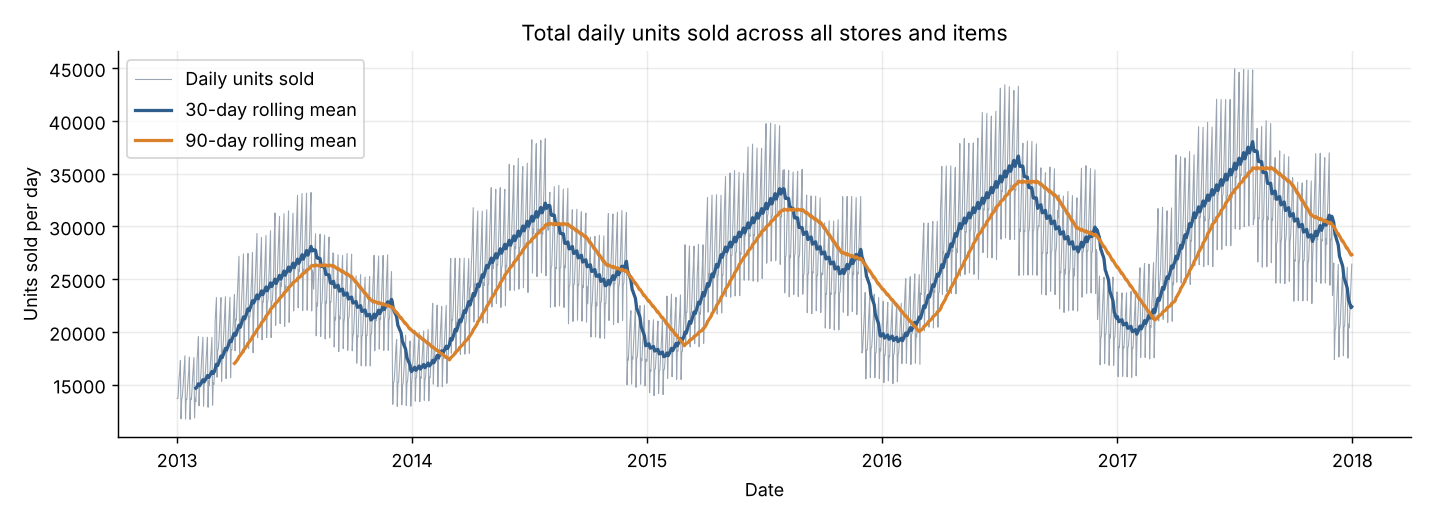

In [4]:
show('01_total_demand_trend.png')

Demand grows every year (2014 +15.0%, 2015 +4.4%, 2016 +8.3%, 2017 +3.9%) with strong yearly waves. The model must carry a level or growth term because trees cannot extrapolate.

## Seasonality

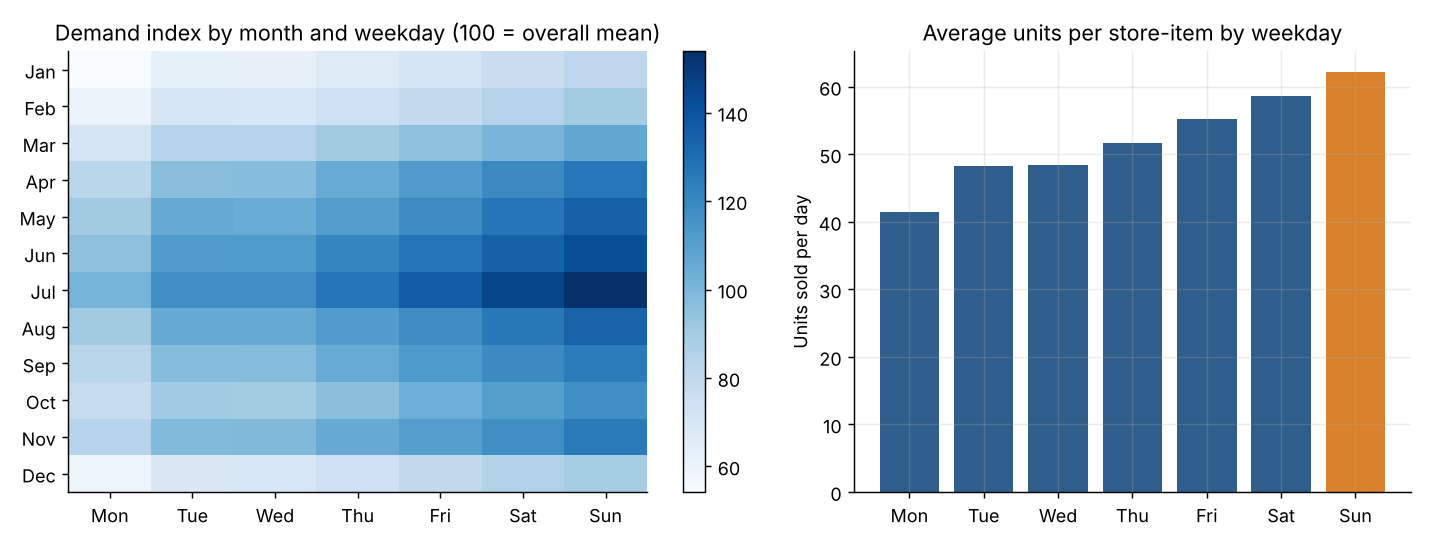

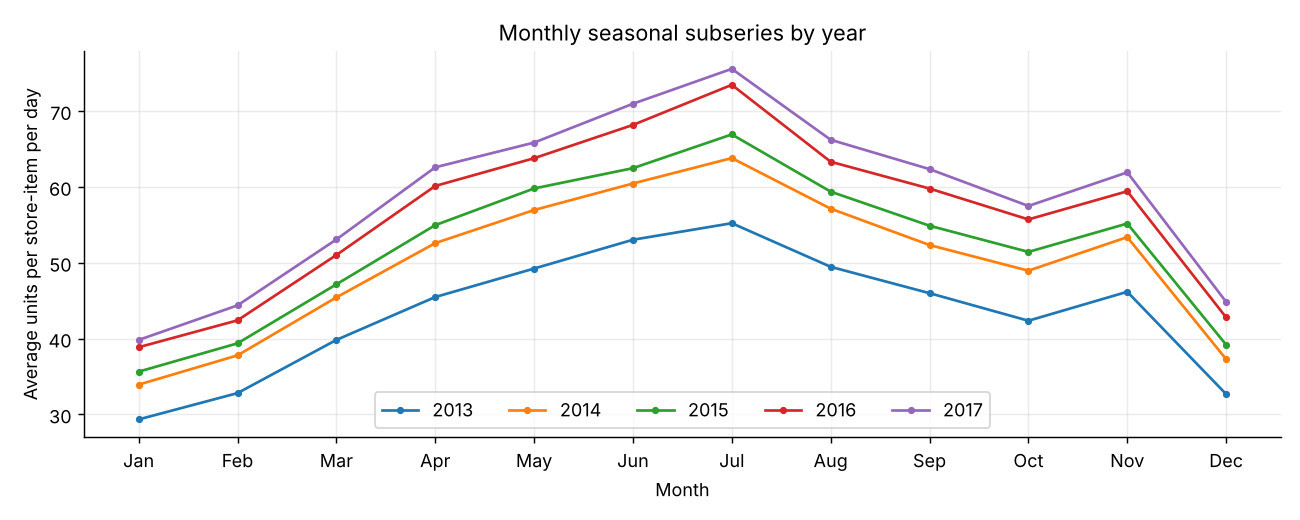

In [5]:
show('02_seasonality_heatmap.png'); show('03_seasonal_subseries.png')

Weekly effect is strong (Monday index 79, Sunday 119). The annual cycle peaks in July (index 128) and bottoms in January (68). The pattern repeats each year, so calendar features can encode it.

## Distribution, stores and items

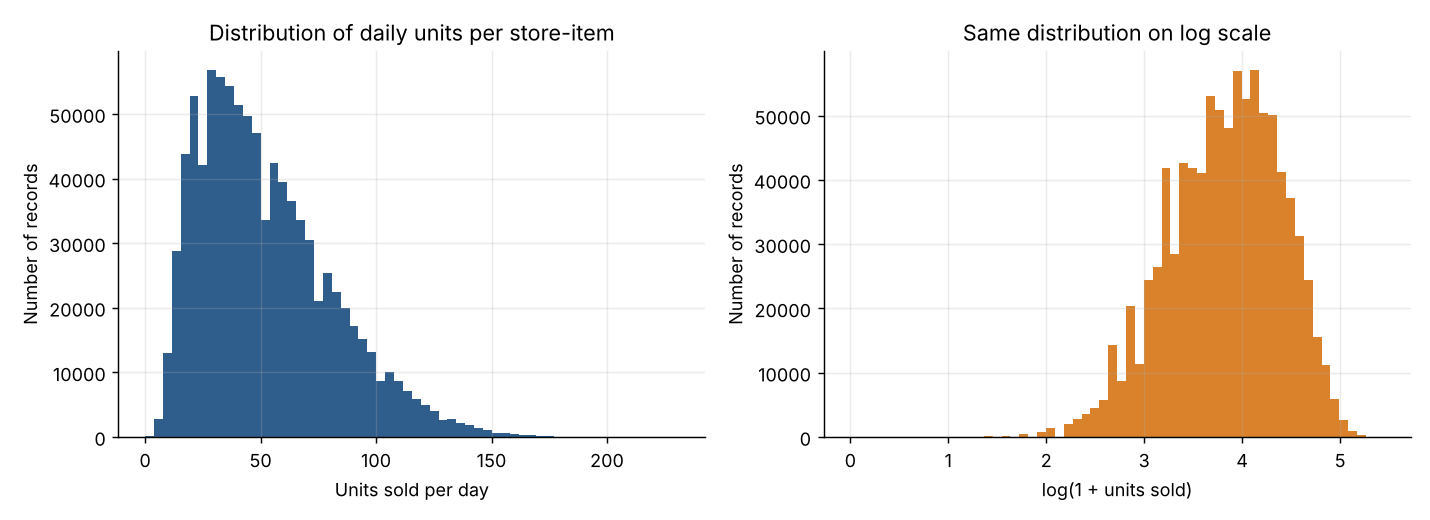

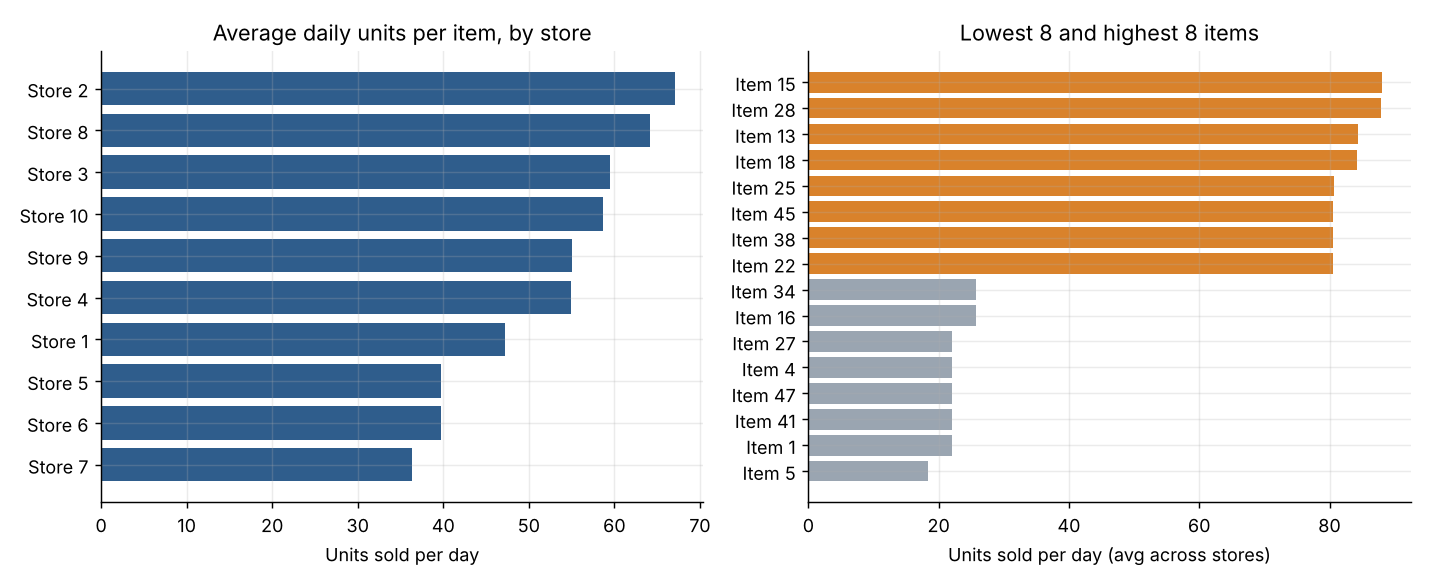

In [6]:
show('04_demand_distribution.png'); show('05_store_item_volume.png')

Demand is mildly right-skewed (skew 0.87, median 47, p99 135) and almost never zero, so the series is smooth rather than intermittent and sMAPE/WAPE are safe to use. Stores differ in level (36 to 67 units per item per day) and items differ in level (18 to 88).

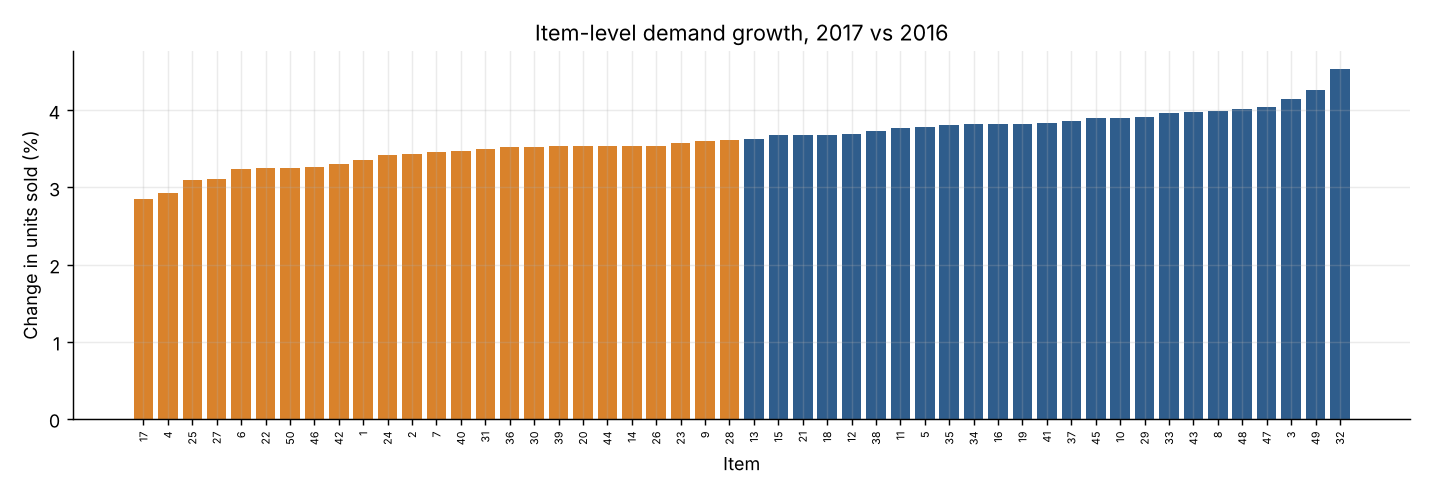

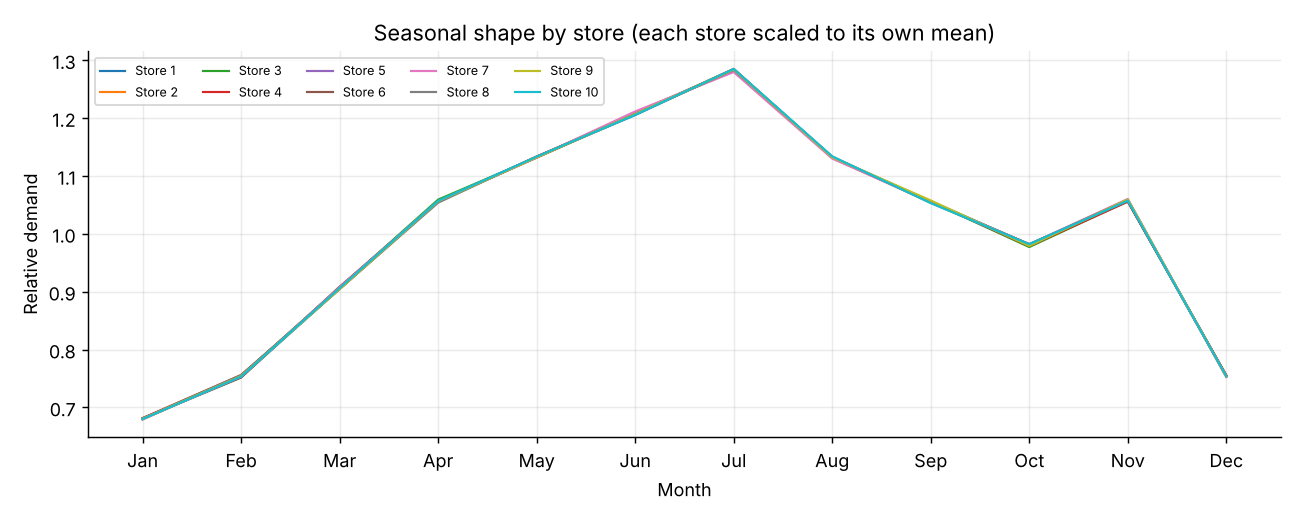

In [7]:
show('06_item_growth.png'); show('07_store_seasonal_shape.png')

All items grew between 2.8% and 4.5% in 2017 and every store has the same seasonal shape. This is a very regular dataset, so one global model across all 500 series is appropriate and rankings of growing or declining items will show small differences.

## Decomposition and stationarity

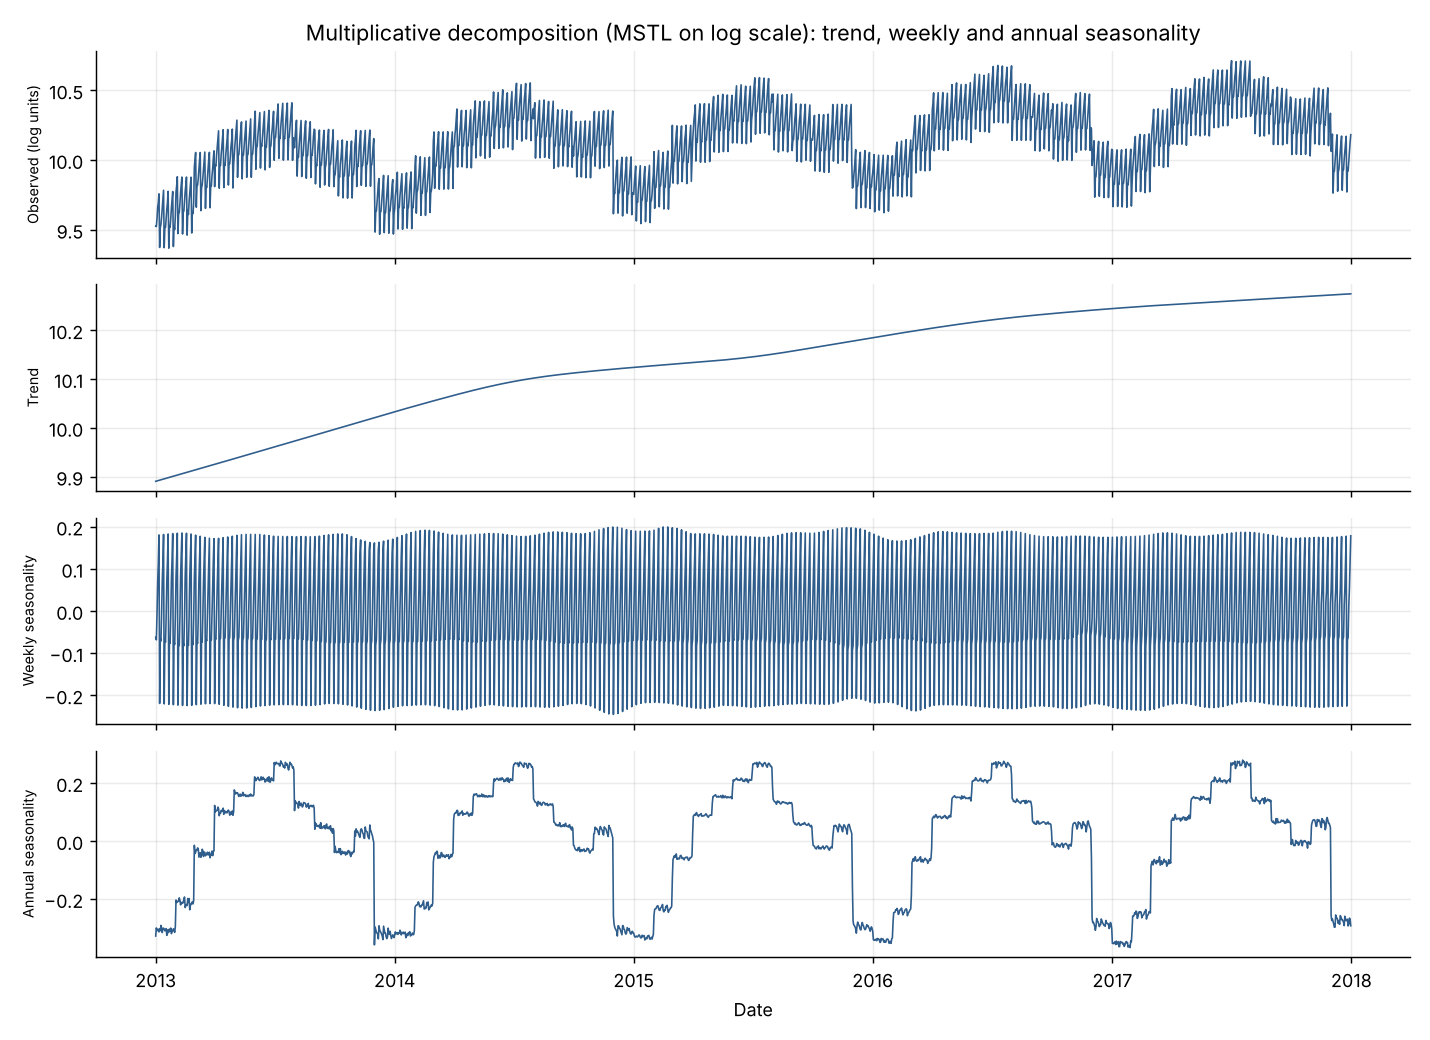

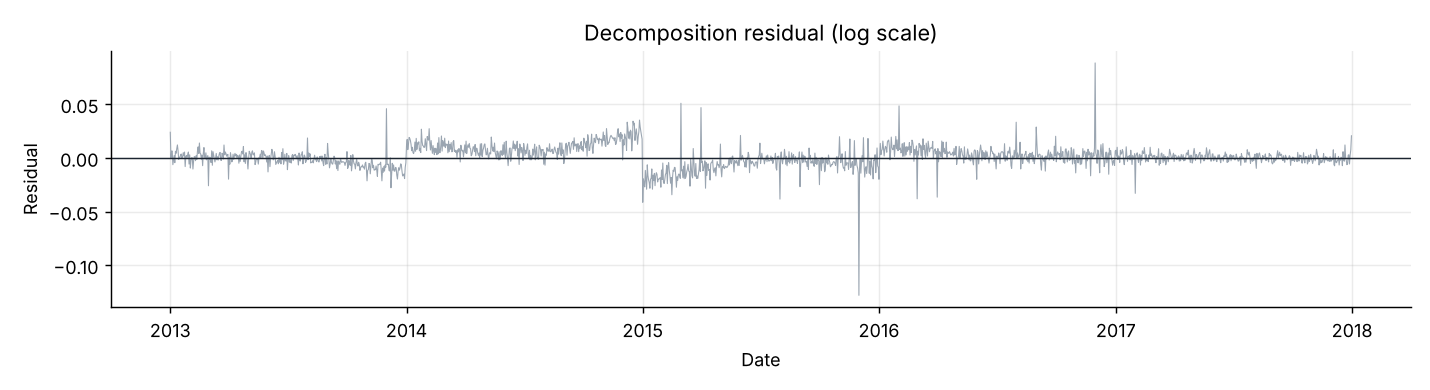

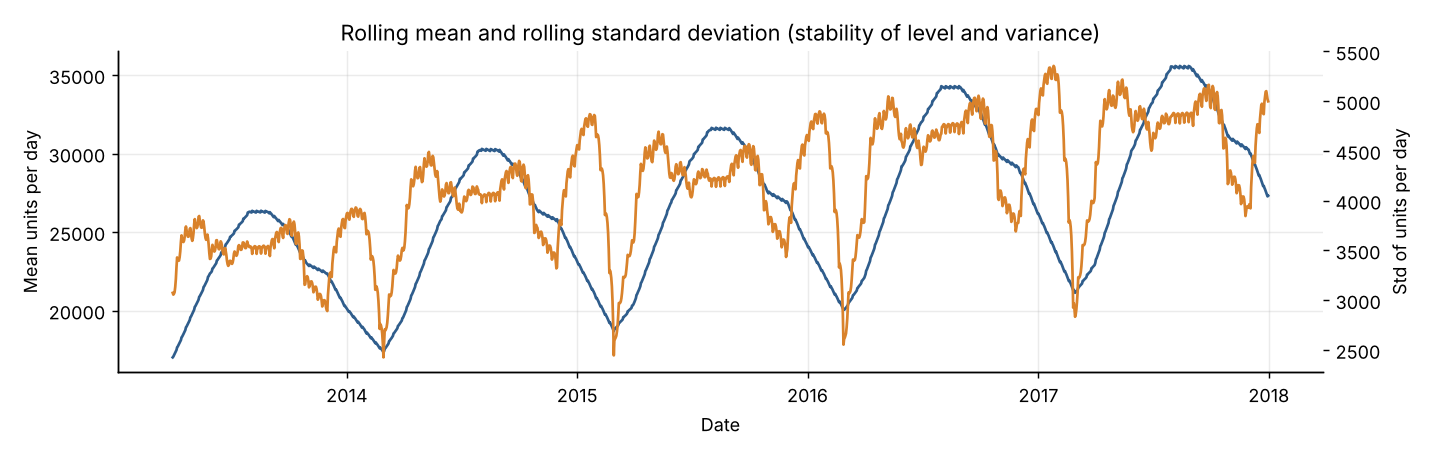

In [8]:
show('08_decomposition.png'); show('09_decomposition_residual.png'); show('10_rolling_stats.png')

In [9]:
print(json.dumps(json.loads((C.REPORTS / 'eda_findings.json').read_text())['decomposition'], indent=1))
print(json.dumps(json.loads((C.REPORTS / 'eda_findings.json').read_text())['stationarity'], indent=1))

{
 "method": "MSTL on log(total daily units), periods 7 and 365 (log-additive = multiplicative)",
 "weekly_amplitude_pct": 43.78765092048389,
 "annual_amplitude_pct": 62.98821219082741,
 "residual_std_log": 0.010053444142818228,
 "residual_autocorr_lag1": 0.5034576151515934,
 "residual_autocorr_lag7": 0.29988316895077377
}
{
 "adf_level_pvalue": 0.029638649268844457,
 "adf_diff1_pvalue": 1.053375681342386e-14,
 "adf_seasonal_diff7_pvalue": 1.1319567411582232e-08,
 "kpss_level_pvalue": 0.01
}


A multiplicative decomposition (MSTL on log demand, periods 7 and 365) was used because the seasonal swing grows with the level of demand. Weekly swing is about 44% and annual swing about 63%. The residual is small (std 0.01 in logs) but autocorrelated (lag-1 0.50, lag-7 0.30), so recent-level and rolling features still add information. The level series is borderline stationary (ADF p=0.03, KPSS p=0.01), and first or seasonal differencing makes it clearly stationary (ADF p<1e-8). This is why the machine-learning route with explicit calendar and lag features was preferred over SARIMA.